<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS10/lab3_js10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1 — Persiapan data XOR

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42)
X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)
print('Data XOR:')
for xi, yi in zip(X, y):
    print(xi.astype(int), '->', int(yi[0]))

Data XOR:
[0 0] -> 0
[0 1] -> 1
[1 0] -> 1
[1 1] -> 0


## Langkah 2 — Fungsi sigmoid dan inisialisasi bobot

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def binary_cross_entropy(y_true, p):
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

rng = np.random.default_rng(42)
W1 = rng.normal(0, 1, (2, 8))
b1 = np.zeros((1, 8))
W2 = rng.normal(0, 1, (8, 1))
b2 = np.zeros((1, 1))
print('Bentuk W1:', W1.shape, '| W2:', W2.shape)

Bentuk W1: (2, 8) | W2: (8, 1)


## Langkah 3 — Forward propagation dan backpropagation
Loss: *binary cross entropy*. Output sigmoid + BCE memberi turunan ringkas `dZ2 = (p-y)/n`.

In [3]:
lr = 1.0
epochs = 12000
history = []
n = len(X)
for epoch in range(epochs):
    # Forward
    Z1 = X @ W1 + b1
    A1 = sigmoid(Z1)
    Z2 = A1 @ W2 + b2
    P = sigmoid(Z2)
    # Loss
    history.append(binary_cross_entropy(y, P))
    # Backprop
    dZ2 = (P - y) / n
    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)
    dZ1 = (dZ2 @ W2.T) * A1 * (1 - A1)
    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0, keepdims=True)
    # Update parameter
    W2 -= lr * dW2
    b2 -= lr * db2
    W1 -= lr * dW1
    b1 -= lr * db1
print('Loss awal:', round(history[0], 5))
print('Loss akhir:', round(history[-1], 5))

Loss awal: 0.76075
Loss akhir: 0.00042


## Langkah 4 — Grafik loss

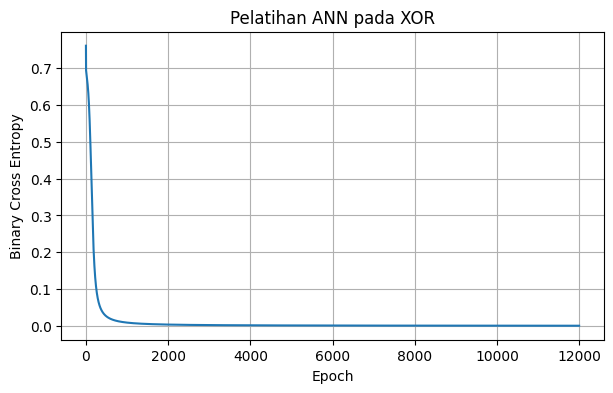

In [4]:
plt.figure(figsize=(7, 4))
plt.plot(history)
plt.xlabel('Epoch'); plt.ylabel('Binary Cross Entropy')
plt.title('Pelatihan ANN pada XOR'); plt.grid(True)
plt.show()

## Langkah 5 — Prediksi XOR

In [5]:
def predict_probability(x):
    a1 = sigmoid(x @ W1 + b1)
    return sigmoid(a1 @ W2 + b2)

prob = predict_probability(X)
ypred = (prob >= 0.5).astype(int)
for x, p, out in zip(X, prob.ravel(), ypred.ravel()):
    print(f'{x.astype(int)} → probabilitas={p:.4f}, prediksi={out}')
print('Akurasi:', accuracy_score(y.ravel(), ypred.ravel()))
print('Confusion matrix:\n', confusion_matrix(y.ravel(), ypred.ravel()))

[0 0] → probabilitas=0.0002, prediksi=0
[0 1] → probabilitas=0.9996, prediksi=1
[1 0] → probabilitas=0.9995, prediksi=1
[1 1] → probabilitas=0.0006, prediksi=0
Akurasi: 1.0
Confusion matrix:
 [[2 0]
 [0 2]]


## Langkah 6 — Decision regions

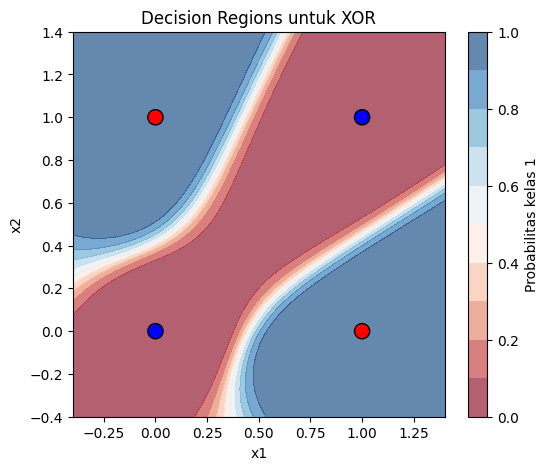

In [6]:
xx, yy = np.meshgrid(np.linspace(-0.4, 1.4, 220), np.linspace(-0.4, 1.4, 220))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = predict_probability(grid).reshape(xx.shape)
plt.figure(figsize=(6, 5))
plt.contourf(xx, yy, zz, levels=np.linspace(0,1,11), cmap='RdBu', alpha=0.65)
plt.colorbar(label='Probabilitas kelas 1')
plt.scatter(X[:,0], X[:,1], c=y.ravel(), cmap='bwr', edgecolors='black', s=120)
plt.xlabel('x1'); plt.ylabel('x2'); plt.title('Decision Regions untuk XOR')
plt.show()

## Kesimpulan

Model dengan hidden layer dapat memisahkan data XOR yang tidak *linearly separable*. Latihan ini memperlihatkan hubungan antara *forward pass*, *loss*, gradien, dan pembaruan parameter menggunakan *gradient descent*.